In [1]:
### Contornos y momentos (forma, área, centroide, etc.)

import cv2

imagen = cv2.imread('manzana.jpg', 0)
_, binaria = cv2.threshold(imagen, 127, 255, cv2.THRESH_BINARY)
contornos, _ = cv2.findContours(binaria, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

for cnt in contornos:
    area = cv2.contourArea(cnt)
    perimetro = cv2.arcLength(cnt, True)
    momentos = cv2.moments(cnt)
    if momentos['m00']==0:momentos['m00']=1
    cx = int(momentos['m10']/momentos['m00'])  # centroide X
    cy = int(momentos['m01']/momentos['m00'])  # centroide Y
    print(f'Área: {area}, Perímetro: {perimetro}, Centroide: ({cx},{cy})')
##Características geométricas y de forma

Área: 50135.0, Perímetro: 912.0, Centroide: (135,92)


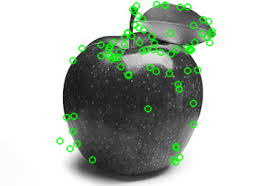

-1

In [7]:
import cv2
from google.colab.patches import cv2_imshow
imagen = cv2.imread('manzana.jpg', 0)
### b. **SIFT o SURF (si tienes OpenCV contrib)**

sift = cv2.SIFT_create()
keypoints, descriptores = sift.detectAndCompute(imagen, None)

imagen_con_kp = cv2.drawKeypoints(imagen, keypoints, None, color=(0, 255, 0))
cv2_imshow(imagen_con_kp)
cv2.waitKey(0)
#Características locales (esquinas, puntos clave)

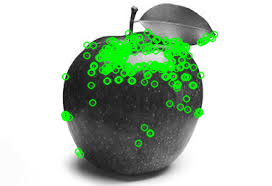

-1

In [8]:
import cv2
from google.colab.patches import cv2_imshow
imagen = cv2.imread('manzana.jpg', 0)
orb = cv2.ORB_create()
keypoints, descriptores = orb.detectAndCompute(imagen, None)

imagen_con_kp = cv2.drawKeypoints(imagen, keypoints, None, color=(0, 255, 0))
cv2_imshow(imagen_con_kp)
cv2.waitKey(0)
#Características locales (esquinas, puntos clave)

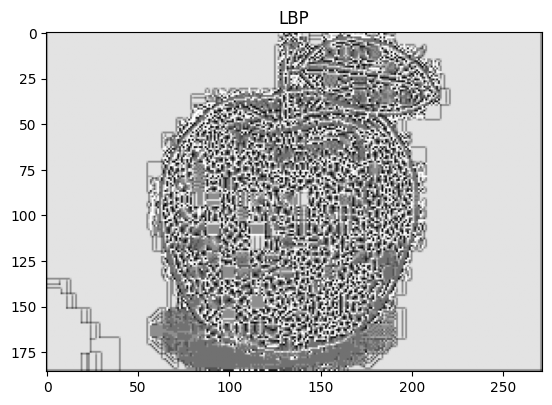

In [9]:
### LBP (Local Binary Pattern) con skimage

from skimage.feature import local_binary_pattern
import cv2
import matplotlib.pyplot as plt

imagen = cv2.imread('manzana.jpg', 0)
lbp = local_binary_pattern(imagen, P=8, R=1, method='uniform')
plt.imshow(lbp, cmap='gray')
plt.title('LBP')
plt.show()
## Características de textura (LBP, GLCM, etc.)

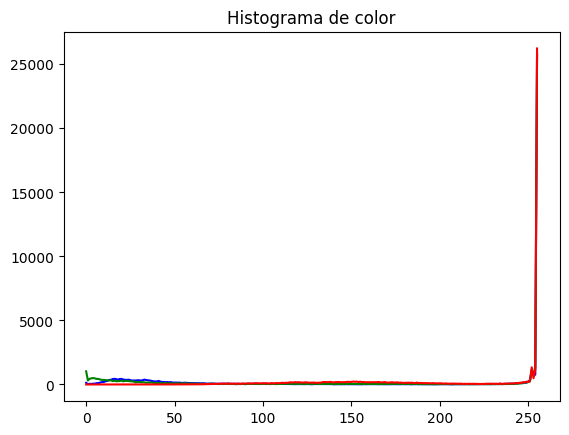

In [10]:
import cv2
import matplotlib.pyplot as plt

imagen = cv2.imread('manzana.jpg')
color = ('b', 'g', 'r')
for i, col in enumerate(color):
    hist = cv2.calcHist([imagen], [i], None, [256], [0, 256])
    plt.plot(hist, color=col)
plt.title('Histograma de color')
plt.show()
#Características basadas en píxeles